In [1]:
from pathlib import Path
import sys

from IPython.display import Image, display


def find_step2_root():
    current = Path.cwd().resolve()
    for candidate in [current, *current.parents]:
        if candidate.name == "schritt2_knotenausfaelle":
            return candidate
        nested = candidate / "schritt2_knotenausfaelle"
        if nested.exists():
            return nested
    return Path(r"C:\Users\test\ba-gamous-disjoint\schritt2_knotenausfaelle")


STEP2_ROOT = find_step2_root()
SRC_ROOT = STEP2_ROOT / "src"
EVALUATION_ROOT = STEP2_ROOT / "evaluation"
OUTPUT_ROOT = EVALUATION_ROOT / "output"
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

STEP2_ROOT

WindowsPath('C:/Users/test/ba-gamous-disjoint/schritt2_knotenausfaelle')

In [2]:
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


ALGORITHMS = [
    ("EDPs", "hopsPath", "#4C78A8", "o"),
    ("One Tree", "hopsRankedOne", "#B54A4A", "x"),
    ("Multiple Trees", "hopsRanked", "#59A14F", "o"),
]


def failure_value_from_path(path):
    match = re.search(r"-ff([^\\/.]+(?:\.[^\\/.]+)?)\.csv$", path.name)
    if match is None:
        return path.stem

    value = match.group(1)
    try:
        return float(value)
    except ValueError:
        return value


def read_result_csv(path):
    df = pd.read_csv(path)
    total = len(df.index)
    if total == 0:
        raise ValueError(f"{path} contains no rows.")

    result = {
        "path": path,
        "failure_value": failure_value_from_path(path),
        "runs": total,
        "avg_failed_nodes": float(df["nrFailedNodes"].mean()) if "nrFailedNodes" in df.columns else np.nan,
    }

    for label, column, _, _ in ALGORITHMS:
        successful = df[column] > -1
        result[f"{label}_resilience"] = float(np.count_nonzero(successful) / total)
        result[f"{label}_avg_hops"] = float(df.loc[successful, column].mean()) if np.any(successful) else np.nan

    return result


def collect_csv_files(inputs):
    csv_files = []
    for input_path in inputs:
        path = Path(input_path)
        if path.is_dir():
            csv_files.extend(sorted(path.glob("*.csv")))
        else:
            csv_files.append(path)

    csv_files = [path for path in csv_files if path.name != "runtime.csv"]
    if not csv_files:
        raise FileNotFoundError("No result CSV files found.")
    return csv_files


def build_summary(inputs):
    rows = [read_result_csv(path) for path in collect_csv_files(inputs)]
    summary = pd.DataFrame(rows)
    return summary.sort_values("failure_value")


def plot_summary(summary, output_path, title):
    fig, (ax_resilience, ax_hops) = plt.subplots(2, 1, figsize=(8, 7), sharex=True)
    x_values = summary["failure_value"]

    for label, _, color, marker in ALGORITHMS:
        ax_resilience.plot(x_values, summary[f"{label}_resilience"], marker=marker, color=color, linewidth=2, label=label)
        ax_hops.plot(x_values, summary[f"{label}_avg_hops"], marker=marker, color=color, linewidth=2, label=label)

    ax_resilience.set_title(title)
    ax_resilience.set_ylabel("Resilience")
    ax_resilience.set_ylim(-0.05, 1.05)
    ax_resilience.grid(True, alpha=0.25)
    ax_resilience.legend()

    ax_hops.set_xlabel("Failure parameter")
    ax_hops.set_ylabel("Avg. Hops")
    ax_hops.grid(True, alpha=0.25)

    fig.tight_layout()
    output_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(output_path, bbox_inches="tight")
    fig.savefig(output_path.with_suffix(".svg"), bbox_inches="tight")
    plt.close(fig)


In [3]:
def show_node_failure_plot(input_dir, output_name, title):
    summary = build_summary([str(input_dir)])
    display(summary)

    output_path = OUTPUT_ROOT / output_name
    plot_summary(summary, output_path, title)
    display(Image(filename=str(output_path)))
    return summary


,path,failure_value,runs,avg_failed_nodes,EDPs_resilience,EDPs_avg_hops,One Tree_resilience,One Tree_avg_hops,Multiple Trees_resilience,Multiple Trees_avg_hops
0,C:\Users\test\ba-gamous-disjoint\schritt2_knot...,0.0,5,0.0,1.0,2.2,1.0,3.0,1.0,3.0
1,C:\Users\test\ba-gamous-disjoint\schritt2_knot...,1.0,5,7.0,1.0,2.0,1.0,3.4,1.0,5.2
7,C:\Users\test\ba-gamous-disjoint\schritt2_knot...,2.0,5,14.0,0.8,2.0,0.8,3.0,0.8,4.0
8,C:\Users\test\ba-gamous-disjoint\schritt2_knot...,3.0,5,21.0,0.0,NaN,0.0,NaN,0.0,NaN
9,C:\Users\test\ba-gamous-disjoint\schritt2_knot...,4.0,5,23.0,0.0,NaN,0.0,NaN,0.0,NaN
10,C:\Users\test\ba-gamous-disjoint\schritt2_knot...,5.0,5,23.0,0.0,NaN,0.0,NaN,0.0,NaN
11,C:\Users\test\ba-gamous-disjoint\schritt2_knot...,6.0,5,23.0,0.0,NaN,0.0,NaN,0.0,NaN
12,C:\Users\test\ba-gamous-disjoint\schritt2_knot...,7.0,5,23.0,0.0,NaN,0.0,NaN,0.0,NaN
13,C:\Users\test\ba-gamous-disjoint\schritt2_knot...,8.0,5,23.0,0.0,NaN,0.0,NaN,0.0,NaN
14,C:\Users\test\ba-gamous-disjoint\schritt2_knot...,9.0,5,23.0,0.0,NaN,0.0,NaN,0.0,NaN


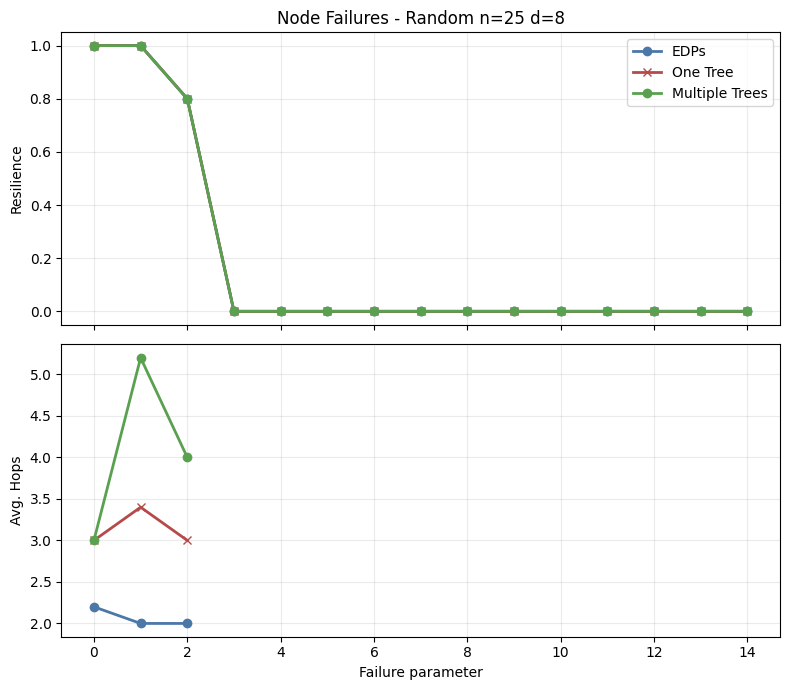

In [4]:
random_n25_p8 = show_node_failure_plot(
    SRC_ROOT / "output_node_random_n25_p8_series",
    "notebook_node_random_n25_p8_series.png",
    "Node Failures - Random n=25 d=8",
)


,path,failure_value,runs,avg_failed_nodes,EDPs_resilience,EDPs_avg_hops,One Tree_resilience,One Tree_avg_hops,Multiple Trees_resilience,Multiple Trees_avg_hops
0,C:\Users\test\ba-gamous-disjoint\schritt2_knot...,0.1,5,0.0,1.0,2.2,1.0,3.000000,1.0,3.0
1,C:\Users\test\ba-gamous-disjoint\schritt2_knot...,0.2,5,1.0,1.0,2.0,1.0,3.000000,1.0,4.2
2,C:\Users\test\ba-gamous-disjoint\schritt2_knot...,0.3,5,2.0,1.0,2.0,1.0,3.200000,1.0,4.6
3,C:\Users\test\ba-gamous-disjoint\schritt2_knot...,0.4,5,4.4,1.0,2.0,1.0,2.600000,1.0,4.8
4,C:\Users\test\ba-gamous-disjoint\schritt2_knot...,0.5,5,7.0,1.0,2.2,1.0,4.800000,1.0,5.6
5,C:\Users\test\ba-gamous-disjoint\schritt2_knot...,0.6,5,9.0,1.0,2.4,1.0,4.800000,1.0,5.6
6,C:\Users\test\ba-gamous-disjoint\schritt2_knot...,0.7,5,12.6,0.6,2.0,0.6,5.333333,0.8,6.0
7,C:\Users\test\ba-gamous-disjoint\schritt2_knot...,0.8,5,15.0,0.4,6.0,0.4,6.000000,0.4,5.0
8,C:\Users\test\ba-gamous-disjoint\schritt2_knot...,0.9,5,18.0,0.0,NaN,0.0,NaN,0.0,NaN


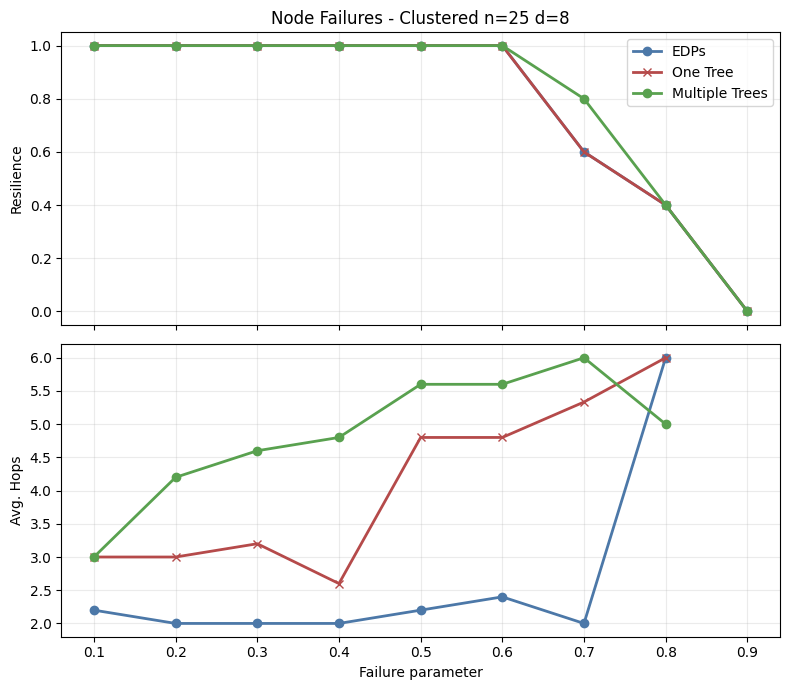

In [5]:
clustered_n25_p8 = show_node_failure_plot(
    SRC_ROOT / "output_node_clustered_n25_p8_series",
    "notebook_node_clustered_n25_p8_series.png",
    "Node Failures - Clustered n=25 d=8",
)


In [6]:
import pandas as pd

column_check_csv = SRC_ROOT / "output_node_random_n25_p8_series" / "trees-p8-n25-ff1.0.csv"
column_check = pd.read_csv(column_check_csv)
display(column_check[["nrFails", "nrFailedNodes", "failureModel", "hopsPath", "hopsRankedOne", "hopsRanked"]])


,nrFails,nrFailedNodes,failureModel,hopsPath,hopsRankedOne,hopsRanked
0,7,7,random,2,3,12
1,7,7,random,2,5,5
2,7,7,random,2,3,3
3,7,7,random,2,3,3
4,7,7,random,2,3,3


In [7]:
import subprocess

test_result = subprocess.run(
    [sys.executable, "-m", "unittest", "discover", "-s", str(STEP2_ROOT / "tests"), "-v"],
    capture_output=True,
    text=True,
)
print(test_result.stdout)
print(test_result.stderr)
assert test_result.returncode == 0


iteration 1
iteration 1

test_clustered_csv_records_failed_node_count_explicitly (test_node_failures.NodeFailureCsvTest.test_clustered_csv_records_failed_node_count_explicitly) ... ok
test_random_csv_records_failed_node_count_explicitly (test_node_failures.NodeFailureCsvTest.test_random_csv_records_failed_node_count_explicitly) ... ok
test_clustered_failures_start_next_to_destination_and_exclude_endpoints (test_node_failures.NodeFailureHelpersTest.test_clustered_failures_start_next_to_destination_and_exclude_endpoints) ... ok
test_edge_conversion_matches_removed_node_shortest_path (test_node_failures.NodeFailureHelpersTest.test_edge_conversion_matches_removed_node_shortest_path) ... ok
test_node_failure_blocks_all_incident_edges_without_duplicates (test_node_failures.NodeFailureHelpersTest.test_node_failure_blocks_all_incident_edges_without_duplicates) ... ok
test_random_node_failures_exclude_source_and_destination (test_node_failures.NodeFailureHelpersTest.test_random_node_failures_ex

In [8]:
import importlib
import networkx as nx

sys.path.insert(0, str(SRC_ROOT))
import kResilienceTrees as trees
trees = importlib.reload(trees)

limit_check_graph = nx.path_graph(5)
requested_failures = 10
selected_failures = trees.getRandomNodeFailures(limit_check_graph, s=0, d=4, nodesToFail=requested_failures)

print("requested:", requested_failures)
print("available intermediate nodes:", [1, 2, 3])
print("selected:", sorted(selected_failures))
assert sorted(selected_failures) == [1, 2, 3]


requested: 10
available intermediate nodes: [1, 2, 3]
selected: [1, 2, 3]
